In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("/content/Mall_Customers.csv")
print(df.shape)
print(df.head())
print(df.describe())
print("Missing values:", df.isnull().sum().sum())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.0000

K= 2 | Inertia=  269.69 | Silhouette=0.321
K= 3 | Inertia=  157.70 | Silhouette=0.467
K= 4 | Inertia=  108.92 | Silhouette=0.494
K= 5 | Inertia=   65.57 | Silhouette=0.555
K= 6 | Inertia=   55.06 | Silhouette=0.540
K= 7 | Inertia=   44.86 | Silhouette=0.528
K= 8 | Inertia=   37.23 | Silhouette=0.455
K= 9 | Inertia=   32.39 | Silhouette=0.457
K=10 | Inertia=   29.98 | Silhouette=0.443


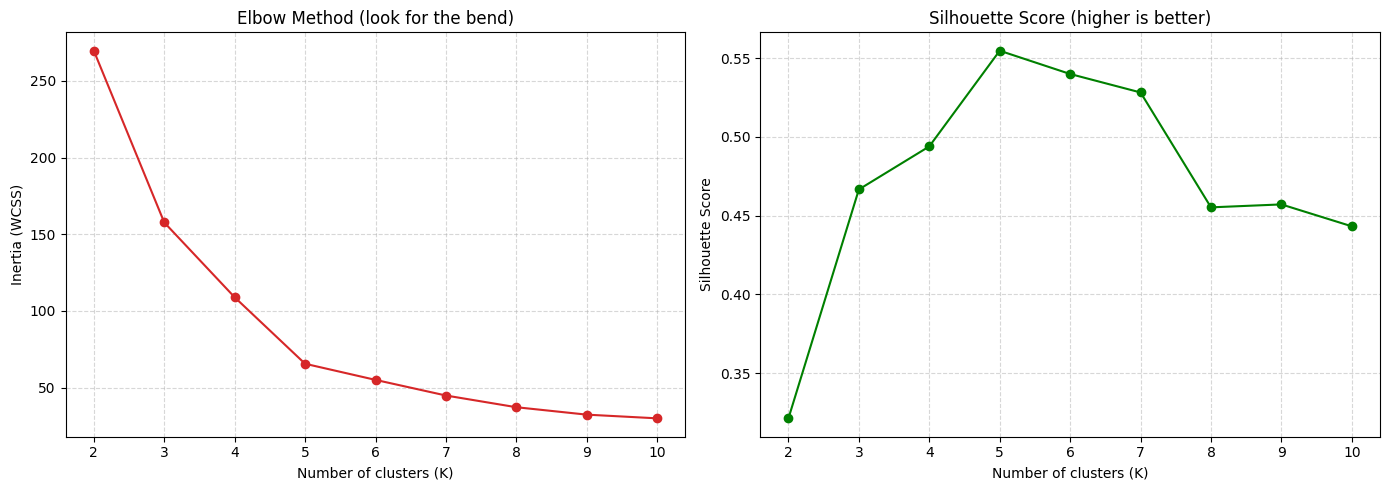

In [6]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
x = df[features]

# Scale the features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# 3. ELBOW METHOD (+ silhouette score) TO FIND THE BEST K
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(x_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(x_scaled, km.labels_))
    print(f"K={k:2d} | Inertia={km.inertia_:8.2f} | Silhouette={silhouettes[-1]:.3f}")

# Plotting the Elbow and Silhouette Scores side-by-side
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
ax[0].plot(list(k_values), inertias, marker="o", color="tab:red")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow Method (look for the bend)")
ax[0].grid(True, linestyle="--", alpha=0.5)

# Silhouette plot
ax[1].plot(list(k_values), silhouettes, marker="o", color="green")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Score (higher is better)")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

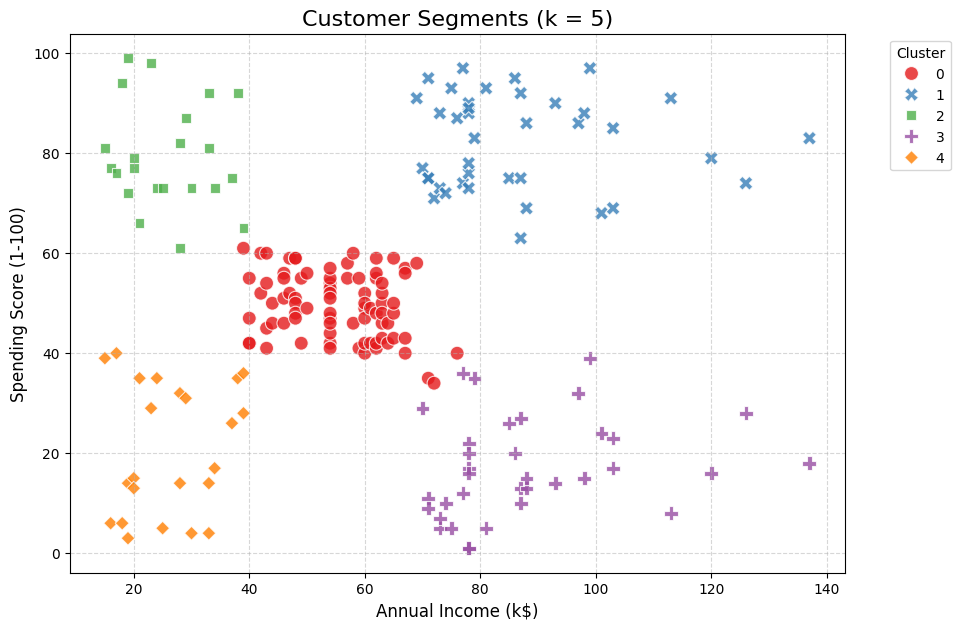

Average characteristics of each cluster:
               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        42.716049           55.296296               49.518519
1        32.692308           86.538462               82.128205
2        25.272727           25.727273               79.363636
3        41.114286           88.200000               17.114286
4        45.217391           26.304348               20.913043


In [8]:
# 4. FIT K-MEANS WITH OPTIMAL K = 5
optimal_k = 5
km_final = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)

# Fit and predict cluster labels
df['Cluster'] = km_final.fit_predict(x_scaled)

# Visualize the resulting customer segments
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    data=df,
    s=100,
    alpha=0.8,
    style='Cluster'
)

plt.title('Customer Segments (k = 5)', fontsize=16)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Display the mean characteristics of each cluster
cluster_summary = df.groupby('Cluster')[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].mean()
print("Average characteristics of each cluster:")
print(cluster_summary)

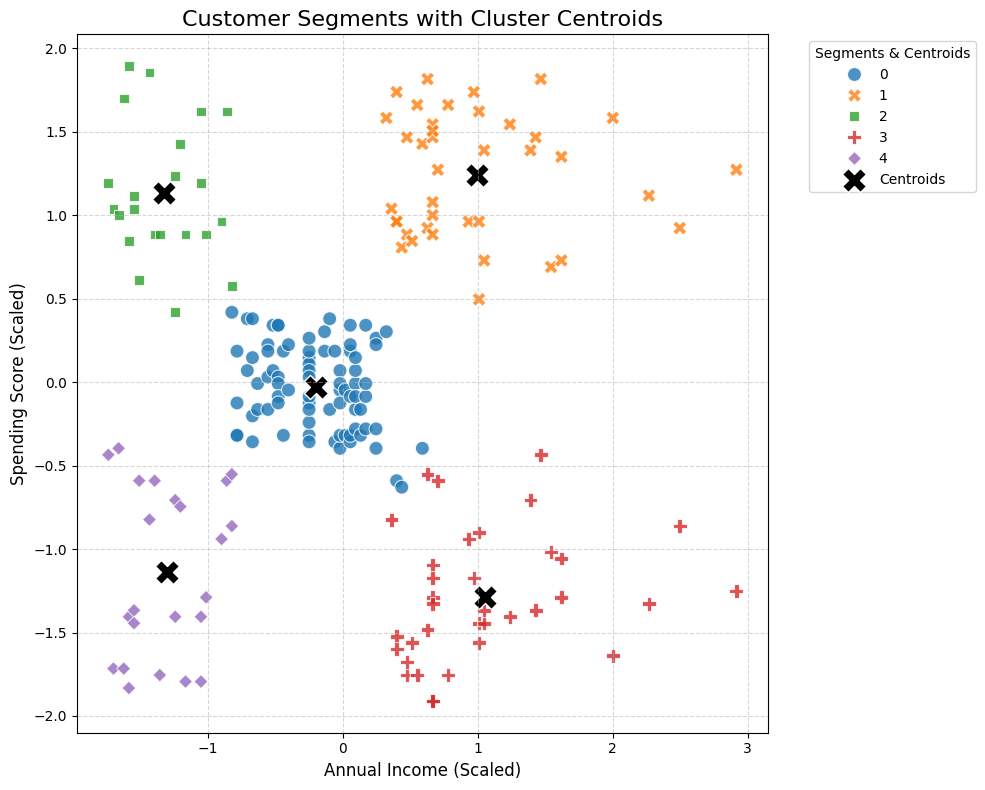

In [10]:
# Visualize the 5 clusters with their centroids
centroids = km_final.cluster_centers_

plt.figure(figsize=(10, 8))
# Plot customer points
sns.scatterplot(
    x=x_scaled[:, 0],
    y=x_scaled[:, 1],
    hue=df['Cluster'],
    palette='tab10',
    s=100,
    alpha=0.8,
    style=df['Cluster']
)

# Plot Centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    s=300,
    c='black',
    marker='X',
    label='Centroids',
    edgecolors='white'
)

plt.title('Customer Segments with Cluster Centroids', fontsize=16)
plt.xlabel('Annual Income (Scaled)', fontsize=12)
plt.ylabel('Spending Score (Scaled)', fontsize=12)
plt.legend(title='Segments & Centroids', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()